In [ ]:

import os
import zipfile

# Find ZIP files uploaded to Colab
zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

print("ZIP files found:", zip_files)

ZIP files found: ['archive (2).zip']


In [ ]:

import os

for f in os.listdir("/content"):
    path = os.path.join("/content", f)
    if os.path.isfile(path):
        print(
            "Filename:", f,
            "| Size:", os.path.getsize(path), "bytes"
        )

        with open(path, "rb") as file:
            print("First 20 bytes:", file.read(20))

        print("-" * 50)

Filename: archive (2).zip | Size: 12582912 bytes
First 20 bytes: b'PK\x03\x04-\x00\x00\x08\x08\x00@raZW\x87\xc2\xef\xff\xff'
--------------------------------------------------


In [ ]:

import zipfile
import os

zip_path = "/content/archive (2).zip"

print("File exists:", os.path.exists(zip_path))
print("File size:", os.path.getsize(zip_path), "bytes")
print("Is ZIP:", zipfile.is_zipfile(zip_path))

try:
    with zipfile.ZipFile(zip_path, "r") as z:
        print("Number of files:", len(z.namelist()))
        print("First 10 entries:", z.namelist()[:10])
        print("Integrity test:", z.testzip())
except Exception as e:
    print("ZIP error:", repr(e))

File exists: True
File size: 74980625 bytes
Is ZIP: True
Number of files: 11519
First 10 entries: ['Combined Dataset/test/Mild Impairment/1 (10).jpg', 'Combined Dataset/test/Mild Impairment/1 (11).jpg', 'Combined Dataset/test/Mild Impairment/1 (14).jpg', 'Combined Dataset/test/Mild Impairment/1 (15).jpg', 'Combined Dataset/test/Mild Impairment/1 (2).jpg', 'Combined Dataset/test/Mild Impairment/1 (25).jpg', 'Combined Dataset/test/Mild Impairment/10 (12).jpg', 'Combined Dataset/test/Mild Impairment/10 (2).jpg', 'Combined Dataset/test/Mild Impairment/10 (7).jpg', 'Combined Dataset/test/Mild Impairment/11 (10).jpg']
Integrity test: None


In [ ]:

import os
import zipfile

zip_path = "/content/archive (2).zip"
extract_path = "/content/alzheimer_data"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

dataset_path = os.path.join(
    extract_path, "Combined Dataset"
)

print("Extraction completed!")
print("Dataset path:", dataset_path)
print("Folders:", os.listdir(dataset_path))

Extraction completed!
Dataset path: /content/alzheimer_data/Combined Dataset
Folders: ['train', 'test']


In [ ]:

import os

dataset_path = "/content/alzheimer_data/Combined Dataset"

for split in ["train", "test"]:
    split_path = os.path.join(dataset_path, split)

    print(f"\n===== {split.upper()} DATASET =====")

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png")
                )
            ]

            print(f"{class_name}: {len(images)} images")


===== TRAIN DATASET =====
Mild Impairment: 2560 images
Moderate Impairment: 2560 images
No Impairment: 2560 images
Very Mild Impairment: 2560 images

===== TEST DATASET =====
Mild Impairment: 179 images
Moderate Impairment: 12 images
No Impairment: 640 images
Very Mild Impairment: 448 images


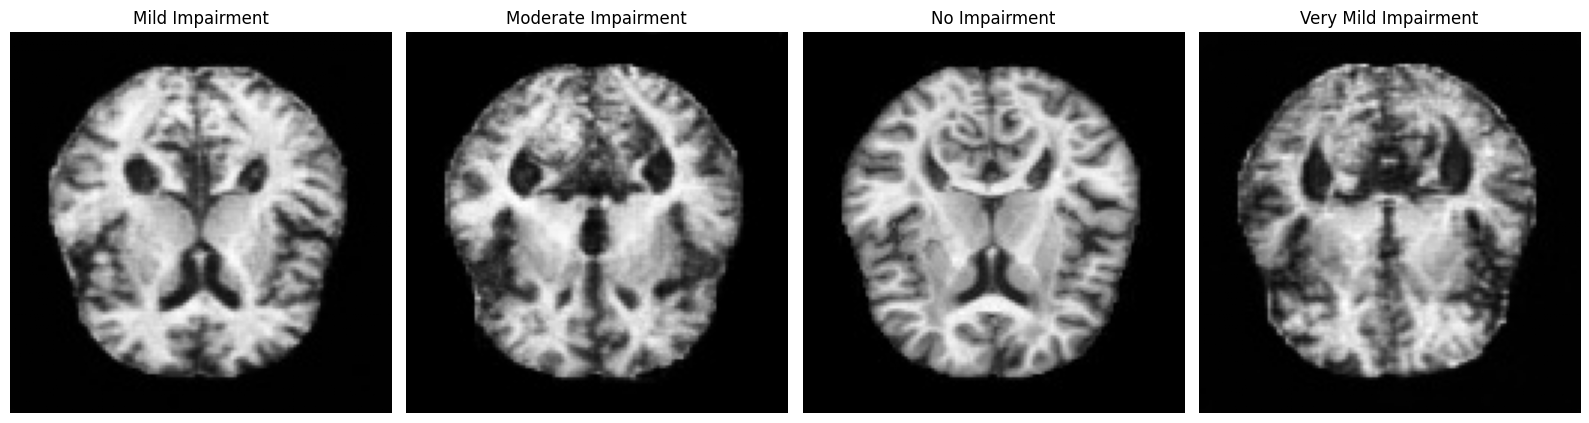

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/alzheimer_data/Combined Dataset"
train_path = os.path.join(dataset_path, "train")

classes = sorted(os.listdir(train_path))

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, class_name in enumerate(classes):
    class_path = os.path.join(train_path, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_path = os.path.join(class_path, image_files[0])
    img = Image.open(image_path)

    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:

import tensorflow as tf
import os

dataset_path = "/content/alzheimer_data/Combined Dataset"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    validation_split=0.2,
    subset="training",
    seed=SEED,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

class_names = train_ds.class_names

# Normalize pixel values from 0–255 to 0–1
normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)
val_ds = val_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)
test_ds = test_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Classes:", class_names)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Preprocessing complete!")

Found 10240 files belonging to 4 classes.
Using 8192 files for training.
Found 10240 files belonging to 4 classes.
Using 2048 files for validation.
Found 1279 files belonging to 4 classes.
Classes: ['Mild Impairment', 'Moderate Impairment', 'No Impairment', 'Very Mild Impairment']
Image size: (128, 128)
Batch size: 32
Preprocessing complete!


In [ ]:

from tensorflow.keras import layers, models

model = models.Sequential([
    # Input MRI image: 128 × 128 pixels, 3 color channels
    layers.Input(shape=(128, 128, 3)),

    # CNN learns important patterns from MRI images
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a one-dimensional vector
    layers.Flatten(),

    # Learn from the extracted features
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Predict one of the four classes
    layers.Dense(4, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [ ]:

EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 291s 1s/step - accuracy: 0.5615 - loss: 0.9298 - val_accuracy: 0.7881 - val_loss: 0.5217
Epoch 2/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 284s 1s/step - accuracy: 0.7500 - loss: 0.5564 - val_accuracy: 0.8418 - val_loss: 0.3749
Epoch 3/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 323s 1s/step - accuracy: 0.7889 - loss: 0.4609 - val_accuracy: 0.8711 - val_loss: 0.3378
Epoch 4/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 334s 1s/step - accuracy: 0.8398 - loss: 0.3631 - val_accuracy: 0.8765 - val_loss: 0.2906
Epoch 5/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 290s 1s/step - accuracy: 0.8610 - loss: 0.3128 - val_accuracy: 0.9219 - val_loss: 0.1929
Epoch 6/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 290s 1s/step - accuracy: 0.8854 - loss: 0.2621 - val_accuracy: 0.9331 - val_loss: 0.1607
Epoch 7/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 281s 1s/step - accuracy: 0.9054 - loss: 0.2207 - val_accuracy: 0.9097 - val_loss: 0.1911
Epoch 8/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 302s 1s/step - accuracy: 0.9187 - loss: 0.1875 - val_accu

In [ ]:

import os

dataset_path = "/.ipynb_checkpoints/archive (2).zip"

if os.path.isdir(dataset_path):
    print("Dataset folder found!")
    print("Contents:", os.listdir(dataset_path))
else:
    print("Folder not found at this path.")

Folder not found at this path.
